In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = sns.load_dataset("titanic")

In [3]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [4]:
df.columns

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alive', 'alone'],
      dtype='object')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [6]:
df.drop(["deck", "embark_town", "alive", "class", "who", "adult_male"], axis=1, inplace=True)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   survived  891 non-null    int64  
 1   pclass    891 non-null    int64  
 2   sex       891 non-null    object 
 3   age       714 non-null    float64
 4   sibsp     891 non-null    int64  
 5   parch     891 non-null    int64  
 6   fare      891 non-null    float64
 7   embarked  889 non-null    object 
 8   alone     891 non-null    bool   
dtypes: bool(1), float64(2), int64(4), object(2)
memory usage: 56.7+ KB


In [8]:
df["age"].fillna(df["age"].mean(), inplace=True)

In [9]:
df.dropna(subset=["embarked"], inplace=True)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 889 entries, 0 to 890
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   survived  889 non-null    int64  
 1   pclass    889 non-null    int64  
 2   sex       889 non-null    object 
 3   age       889 non-null    float64
 4   sibsp     889 non-null    int64  
 5   parch     889 non-null    int64  
 6   fare      889 non-null    float64
 7   embarked  889 non-null    object 
 8   alone     889 non-null    bool   
dtypes: bool(1), float64(2), int64(4), object(2)
memory usage: 63.4+ KB


In [11]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

In [12]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,alone
0,0,3,male,22.0,1,0,7.2500,S,False
1,1,1,female,38.0,1,0,71.2833,C,False
2,1,3,female,26.0,0,0,7.9250,S,True
3,1,1,female,35.0,1,0,53.1000,S,False
4,0,3,male,35.0,0,0,8.0500,S,True


In [13]:
df['sex'] = le.fit_transform(df['sex'])
df["embarked"] = le.fit_transform(df["embarked"]) # S=2, C=0, Q=1

In [14]:

df = df.astype(int)

In [15]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,alone
0,0,3,1,22,1,0,7,2,0
1,1,1,0,38,1,0,71,0,0
2,1,3,0,26,0,0,7,2,1
3,1,1,0,35,1,0,53,2,0
4,0,3,1,35,0,0,8,2,1


In [16]:
X = df.drop("survived", axis=1)
y = df["survived"]

In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [18]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()

model.fit(X_train,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [19]:
y_pred = model.predict(X_test)

In [20]:
y_pred

array([0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0,
       0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0,
       0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0,
       0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0,
       0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0,
       0, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1,
       0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0,
       0, 1])

In [21]:
y_test

281    0
435    1
39     1
418    0
585    1
      ..
433    0
807    0
25     1
85     1
10     1
Name: survived, Length: 178, dtype: int64

In [22]:
from sklearn.metrics import accuracy_score, confusion_matrix , classification_report

In [23]:
accuracy_score(y_test,y_pred)

0.8033707865168539

In [24]:
confusion_matrix(y_test,y_pred)

array([[90, 19],
       [16, 53]])

In [25]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.85      0.83      0.84       109
           1       0.74      0.77      0.75        69

    accuracy                           0.80       178
   macro avg       0.79      0.80      0.79       178
weighted avg       0.81      0.80      0.80       178



In [26]:
df

,survived,pclass,sex,age,sibsp,parch,fare,embarked,alone
0,0,3,1,22,1,0,7,2,0
1,1,1,0,38,1,0,71,0,0
2,1,3,0,26,0,0,7,2,1
3,1,1,0,35,1,0,53,2,0
4,0,3,1,35,0,0,8,2,1
...,...,...,...,...,...,...,...,...,...
886,0,2,1,27,0,0,13,2,1
887,1,1,0,19,0,0,30,2,1
888,0,3,0,29,1,2,23,2,0
889,1,1,1,26,0,0,30,0,1


In [27]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [28]:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)

In [29]:
from sklearn.neighbors import KNeighborsClassifier

In [30]:
knn_model = KNeighborsClassifier(n_neighbors= 5)
knn_model.fit(X_train_scaled,y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [31]:
y_pred_knn = knn_model.predict(X_test_scaled)

In [32]:
accuracy_score(y_test,y_pred_knn)

0.7808988764044944

In [33]:
confusion_matrix(y_test,y_pred_knn)

array([[90, 19],
       [20, 49]])

In [34]:
print(classification_report(y_test,y_pred_knn))

              precision    recall  f1-score   support

           0       0.82      0.83      0.82       109
           1       0.72      0.71      0.72        69

    accuracy                           0.78       178
   macro avg       0.77      0.77      0.77       178
weighted avg       0.78      0.78      0.78       178



In [35]:
from sklearn.naive_bayes import GaussianNB

In [36]:
model_NB = GaussianNB()

In [37]:
model_NB.fit(X_train,y_train)

,priors,None
,var_smoothing,1e-09


In [38]:
y_pred_NB = model_NB.predict(X_test)

In [39]:
y_pred_NB

array([0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1,
       0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0,
       0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0,
       0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0,
       0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0,
       0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0,
       0, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0,
       0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0,
       0, 1])

In [40]:
accuracy_score(y_test,y_pred_NB)

0.7752808988764045

In [41]:
confusion_matrix(y_test,y_pred_NB)

array([[84, 25],
       [15, 54]])

In [42]:
print(classification_report(y_test,y_pred_NB))

              precision    recall  f1-score   support

           0       0.85      0.77      0.81       109
           1       0.68      0.78      0.73        69

    accuracy                           0.78       178
   macro avg       0.77      0.78      0.77       178
weighted avg       0.78      0.78      0.78       178



In [43]:
from sklearn.tree import DecisionTreeClassifier

In [44]:
model_DT = DecisionTreeClassifier(random_state=42)

In [45]:
model_DT.fit(X_train_scaled,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [46]:
y_pred_DT = model_DT.predict(X_test_scaled)

In [47]:
y_pred_DT

array([0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1,
       0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0,
       1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0,
       0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0,
       0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0,
       0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0,
       0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1,
       0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0,
       1, 0])

In [48]:
accuracy_score(y_test,y_pred_DT)

0.7696629213483146

In [49]:
confusion_matrix(y_test,y_pred_DT)

array([[88, 21],
       [20, 49]])

In [50]:
print(classification_report(y_test,y_pred_DT))

              precision    recall  f1-score   support

           0       0.81      0.81      0.81       109
           1       0.70      0.71      0.71        69

    accuracy                           0.77       178
   macro avg       0.76      0.76      0.76       178
weighted avg       0.77      0.77      0.77       178



### 🌲 DECISION TREE PRUNING: PRE-PRUNING vs POST-PRUNING
An unconstrained decision tree splits until leaves are 100% pure, causing extreme **overfitting** (high variance, memorizing noise).

1. **Pre-Pruning (Early Stopping)**: Halting tree construction before it becomes too complex by constraining hyperparameters:
   - `max_depth`: Limits maximum depth of the tree.
   - `min_samples_split`: Minimum samples required to split an internal node.
   - `min_samples_leaf`: Minimum samples required in a terminal leaf node.
   - `max_leaf_nodes`: Upper bound on the total number of leaves.

2. **Post-Pruning (Cost-Complexity Pruning via `ccp_alpha`)**:
   - The tree is allowed to grow fully, then subtrees with minimal impurity reduction are pruned backward.
   - Cost function: $R_\alpha(T) = R(T) + \alpha |T|$ where $R(T)$ is classification error, $|T|$ is number of terminal leaves, and $\alpha$ is the complexity penalty parameter.
   - As $\alpha$ increases, more nodes are pruned.

In [51]:
# --- 1. PRE-PRUNING EXAMPLE --- 
# Unpruned (overfitted) tree vs Pre-pruned tree
dt_unpruned = DecisionTreeClassifier(random_state=42)
dt_unpruned.fit(X_train_scaled, y_train)

dt_prepruned = DecisionTreeClassifier(max_depth=3, min_samples_split=10, min_samples_leaf=5, random_state=42)
dt_prepruned.fit(X_train_scaled, y_train)

print("=== PRE-PRUNING COMPARISON ===")
print(f"Unpruned Tree:  Train Acc = {dt_unpruned.score(X_train_scaled, y_train)*100:.2f}% | Test Acc = {dt_unpruned.score(X_test_scaled, y_test)*100:.2f}% | Max Depth = {dt_unpruned.get_depth()} | Leaves = {dt_unpruned.get_n_leaves()}")
print(f"Pre-pruned Tree: Train Acc = {dt_prepruned.score(X_train_scaled, y_train)*100:.2f}% | Test Acc = {dt_prepruned.score(X_test_scaled, y_test)*100:.2f}% | Max Depth = {dt_prepruned.get_depth()} | Leaves = {dt_prepruned.get_n_leaves()}")

=== PRE-PRUNING COMPARISON ===
Unpruned Tree:  Train Acc = 96.62% | Test Acc = 76.97% | Max Depth = 24 | Leaves = 167
Pre-pruned Tree: Train Acc = 81.58% | Test Acc = 82.58% | Max Depth = 3 | Leaves = 8


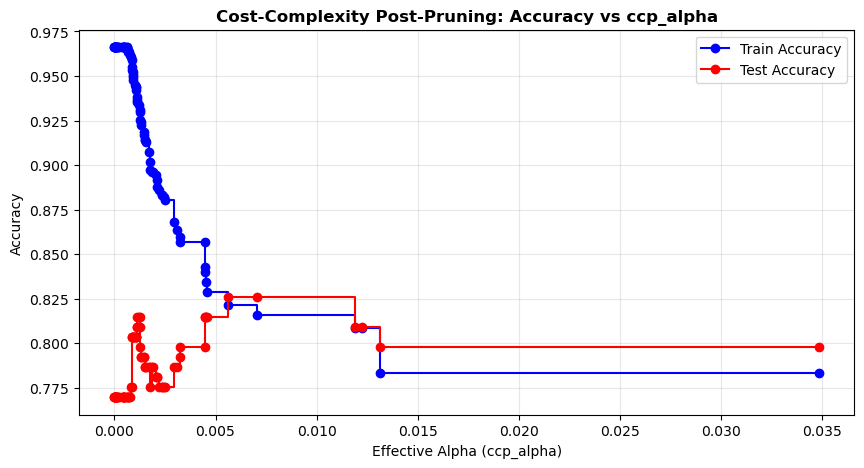

Optimal ccp_alpha: 0.00561
Post-pruned Tree Test Accuracy: 82.58%
Node count reduced from 333 to 13


In [52]:
# --- 2. POST-PRUNING (Cost-Complexity Pruning path via ccp_alpha) ---
path = dt_unpruned.cost_complexity_pruning_path(X_train_scaled, y_train)
ccp_alphas, impurities = path.ccp_alphas, path.impurities

# Train a decision tree for each alpha in the pruning path (excluding the extreme root-only alpha)
clfs = []
for alpha in ccp_alphas[:-1]:
    clf = DecisionTreeClassifier(random_state=42, ccp_alpha=alpha)
    clf.fit(X_train_scaled, y_train)
    clfs.append(clf)

train_scores = [clf.score(X_train_scaled, y_train) for clf in clfs]
test_scores = [clf.score(X_test_scaled, y_test) for clf in clfs]

# Plot Accuracy vs Alpha for Training and Testing sets
plt.figure(figsize=(10, 5))
plt.plot(ccp_alphas[:-1], train_scores, marker='o', label='Train Accuracy', drawstyle='steps-post', color='blue')
plt.plot(ccp_alphas[:-1], test_scores, marker='o', label='Test Accuracy', drawstyle='steps-post', color='red')
plt.xlabel('Effective Alpha (ccp_alpha)')
plt.ylabel('Accuracy')
plt.title('Cost-Complexity Post-Pruning: Accuracy vs ccp_alpha', fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Select the optimal alpha that maximizes test accuracy
best_idx = np.argmax(test_scores)
optimal_alpha = ccp_alphas[best_idx]

dt_postpruned = DecisionTreeClassifier(random_state=42, ccp_alpha=optimal_alpha)
dt_postpruned.fit(X_train_scaled, y_train)

print(f"Optimal ccp_alpha: {optimal_alpha:.5f}")
print(f"Post-pruned Tree Test Accuracy: {dt_postpruned.score(X_test_scaled, y_test)*100:.2f}%")
print(f"Node count reduced from {dt_unpruned.tree_.node_count} to {dt_postpruned.tree_.node_count}")

In [53]:
from sklearn.svm import SVC

In [54]:
model_svm = SVC(kernel = 'linear')

In [55]:
model_svm.fit(X_train_scaled, y_train)


,C,1.0
,kernel,'linear'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [56]:
y_pred_svc = model_svm.predict(X_test_scaled)

In [57]:
accuracy_score(y_test,y_pred_svc)

0.8033707865168539

In [58]:
confusion_matrix(y_test,y_pred_svc)

array([[91, 18],
       [17, 52]])

In [59]:
print(classification_report(y_test,y_pred_svc))

              precision    recall  f1-score   support

           0       0.84      0.83      0.84       109
           1       0.74      0.75      0.75        69

    accuracy                           0.80       178
   macro avg       0.79      0.79      0.79       178
weighted avg       0.80      0.80      0.80       178



### ⚡ SUPPORT VECTOR REGRESSION (SVR): EXTENDING SVM TO CONTINUOUS TARGETS
While **SVC** finds a hyperplane maximizing the margin between discrete classes, **SVR (Support Vector Regressor)** extends this principle to continuous target prediction.

#### Key Mathematical Differences:
- **$\epsilon$-Insensitive Tube**: Points whose errors are within $\pm \epsilon$ of the prediction line incur **zero loss** ($|y - \hat{y}| \le \epsilon$).
- **Slack Variables ($\xi, \xi^*$)**: Only points lying **outside** the $\epsilon$-tube incur a penalty with regularizer $C$.
- **Support Vectors**: Only the points on or outside the $\pm \epsilon$ boundary define the regression function, ensuring sparse solutions!

In [60]:
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Example 1: SVR on continuous target (predicting continuous Age or Fare)
# We predict 'fare' using the other features to demonstrate SVR directly on this dataset
X_svr = df.drop('fare', axis=1)
y_svr = df['fare']

X_tr_svr, X_te_svr, y_tr_svr, y_te_svr = train_test_split(X_svr, y_svr, test_size=0.2, random_state=42)
scaler_svr = StandardScaler()
X_tr_svr_sc = scaler_svr.fit_transform(X_tr_svr)
X_te_svr_sc = scaler_svr.transform(X_te_svr)

# Fit SVR with RBF kernel and epsilon-tube
model_svr = SVR(kernel='rbf', C=50.0, epsilon=2.0)
model_svr.fit(X_tr_svr_sc, y_tr_svr)
y_pred_svr = model_svr.predict(X_te_svr_sc)

r2_svr = r2_score(y_te_svr, y_pred_svr)
rmse_svr = np.sqrt(mean_squared_error(y_te_svr, y_pred_svr))
mae_svr = mean_absolute_error(y_te_svr, y_pred_svr)

print("=== SUPPORT VECTOR REGRESSOR (SVR) EVALUATION ===")
print(f"Kernel:       RBF (Gaussian)")
print(f"C Parameter:  50.0")
print(f"Epsilon Tube: 2.0 (Errors <= 2.0 have 0 penalty)")
print(f"MAE:          ${mae_svr:.2f}")
print(f"RMSE:         ${rmse_svr:.2f}")
print(f"R2 Score:     {r2_svr:.4f}")
print(f"Support Vectors count: {len(model_svr.support_)} out of {len(X_tr_svr)} training points")

=== SUPPORT VECTOR REGRESSOR (SVR) EVALUATION ===
Kernel:       RBF (Gaussian)
C Parameter:  50.0
Epsilon Tube: 2.0 (Errors <= 2.0 have 0 penalty)
MAE:          $12.29
RMSE:         $42.44
R2 Score:     0.3252
Support Vectors count: 397 out of 711 training points


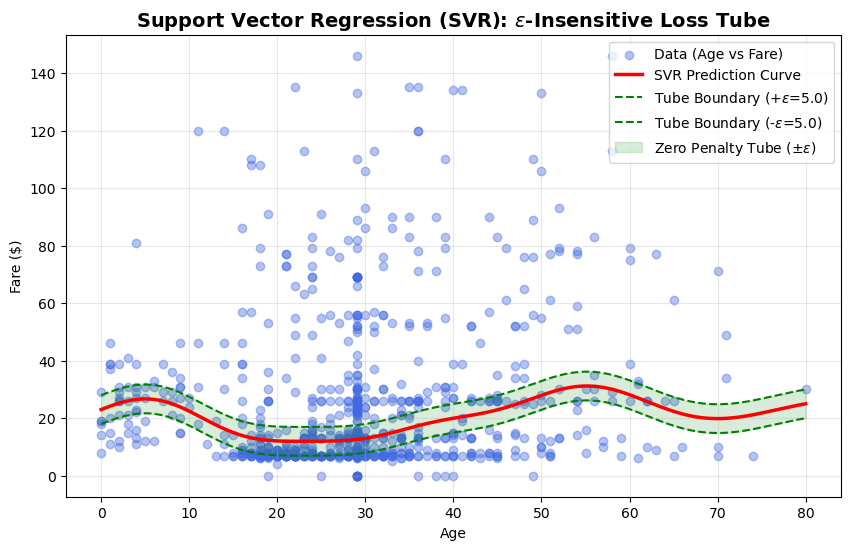

In [61]:
# Visualizing SVR Epsilon-Insensitive Tube on 1D feature slice (Age vs Fare)
X_1d = df[['age']].values
y_1d = df['fare'].values

# Filter reasonable range for clean visualization
mask = (y_1d < 150) & (~np.isnan(X_1d.ravel()))
X_1d_clean = X_1d[mask]
y_1d_clean = y_1d[mask]

sc_1d = StandardScaler()
X_1d_sc = sc_1d.fit_transform(X_1d_clean)

svr_slice = SVR(kernel='rbf', C=20, epsilon=5.0).fit(X_1d_sc, y_1d_clean)

X_grid = np.linspace(X_1d_sc.min(), X_1d_sc.max(), 300).reshape(-1, 1)
y_grid_pred = svr_slice.predict(X_grid)
X_grid_orig = sc_1d.inverse_transform(X_grid)

plt.figure(figsize=(10, 6))
plt.scatter(X_1d_clean, y_1d_clean, color='royalblue', alpha=0.4, label='Data (Age vs Fare)')
plt.plot(X_grid_orig, y_grid_pred, color='red', linewidth=2.5, label='SVR Prediction Curve')
plt.plot(X_grid_orig, y_grid_pred + 5.0, color='green', linestyle='--', linewidth=1.5, label=r'Tube Boundary (+$\epsilon$=5.0)')
plt.plot(X_grid_orig, y_grid_pred - 5.0, color='green', linestyle='--', linewidth=1.5, label=r'Tube Boundary (-$\epsilon$=5.0)')
plt.fill_between(X_grid_orig.ravel(), y_grid_pred - 5.0, y_grid_pred + 5.0, color='green', alpha=0.15, label=r'Zero Penalty Tube ($\pm \epsilon$)')
plt.title(r'Support Vector Regression (SVR): $\epsilon$-Insensitive Loss Tube', fontsize=14, fontweight='bold')
plt.xlabel('Age')
plt.ylabel('Fare ($)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [62]:
#now Lets see what cross validation can do

In [63]:
df

,survived,pclass,sex,age,sibsp,parch,fare,embarked,alone
0,0,3,1,22,1,0,7,2,0
1,1,1,0,38,1,0,71,0,0
2,1,3,0,26,0,0,7,2,1
3,1,1,0,35,1,0,53,2,0
4,0,3,1,35,0,0,8,2,1
...,...,...,...,...,...,...,...,...,...
886,0,2,1,27,0,0,13,2,1
887,1,1,0,19,0,0,30,2,1
888,0,3,0,29,1,2,23,2,0
889,1,1,1,26,0,0,30,0,1


In [64]:
X = df.drop('survived',axis = 1)
y = df['survived']

In [65]:
from sklearn.model_selection import cross_val_score

In [66]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [67]:
scores = cross_val_score(model_svm,X_scaled,y,cv = 5,scoring= 'accuracy')

In [68]:
print(scores)

[0.80337079 0.80898876 0.78651685 0.75280899 0.78531073]


In [69]:
print(scores.mean())

0.7873992255443407


# ------------------------------------------------------------------------------------
## 🎯 MULTI-MODEL BENCHMARK, ROC-AUC ANALYSIS & CLASSIFICATION INTERVIEW MASTERY
### Topics Covered:
1. **Side-by-Side Model Comparison**: Logistic Regression, KNN, Naive Bayes, Decision Tree, Support Vector Machine
2. **ROC Curves & AUC Scores**: Plotting and comparing discrimination thresholds
3. **Confusion Matrix Heatmap Visualizations**
4. **Dual Algorithm Insight**: How Decision Tree, KNN, and SVM adapt to **Regression** tasks
5. **Top 15 Machine Learning Interview Questions on Classification**
# ------------------------------------------------------------------------------------

In [70]:
# Multi-model benchmark summary table with SELECTIVITY / SPECIFICITY
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

def get_metrics(y_true, y_pred, name):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    acc = (tp + tn) / (tp + tn + fp + fn)
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0  # Sensitivity / Recall
    selectivity = tn / (tn + fp) if (tn + fp) > 0 else 0  # Selectivity / Specificity
    f1 = 2 * (prec * rec) / (prec + rec) if (prec + rec) > 0 else 0
    return {
        'Model': name,
        'Accuracy': f"{acc*100:.2f}%",
        'Precision': f"{prec:.4f}",
        'Recall (Sensitivity)': f"{rec:.4f}",
        'Selectivity (TN/(TN+FP))': f"{selectivity:.4f}",
        'F1-Score': f"{f1:.4f}"
    }

models_summary = [
    get_metrics(y_test, y_pred, 'Logistic Regression'),
    get_metrics(y_test, y_pred_knn, 'KNN (k=5)'),
    get_metrics(y_test, y_pred_NB, 'Naive Bayes (Gaussian)'),
    get_metrics(y_test, y_pred_DT, 'Decision Tree (Unpruned)'),
    get_metrics(y_test, dt_prepruned.predict(X_test_scaled), 'Decision Tree (Pre-Pruned)'),
    get_metrics(y_test, dt_postpruned.predict(X_test_scaled), 'Decision Tree (Post-Pruned)'),
    get_metrics(y_test, y_pred_svc, 'SVM (Linear Kernel)')
]

clf_summary_df = pd.DataFrame(models_summary)
print("=== COMPREHENSIVE CLASSIFICATION BENCHMARK WITH SELECTIVITY ===")
display(clf_summary_df)

=== COMPREHENSIVE CLASSIFICATION BENCHMARK WITH SELECTIVITY ===


,Model,Accuracy,Precision,Recall (Sensitivity),Selectivity (TN/(TN+FP)),F1-Score
0,Logistic Regression,80.34%,0.7361,0.7681,0.8257,0.7518
1,KNN (k=5),78.09%,0.7206,0.7101,0.8257,0.7153
2,Naive Bayes (Gaussian),77.53%,0.6835,0.7826,0.7706,0.7297
3,Decision Tree (Unpruned),76.97%,0.7000,0.7101,0.8073,0.7050
4,Decision Tree (Pre-Pruned),82.58%,0.7639,0.7971,0.8440,0.7801
5,Decision Tree (Post-Pruned),82.58%,0.7639,0.7971,0.8440,0.7801
6,SVM (Linear Kernel),80.34%,0.7429,0.7536,0.8349,0.7482


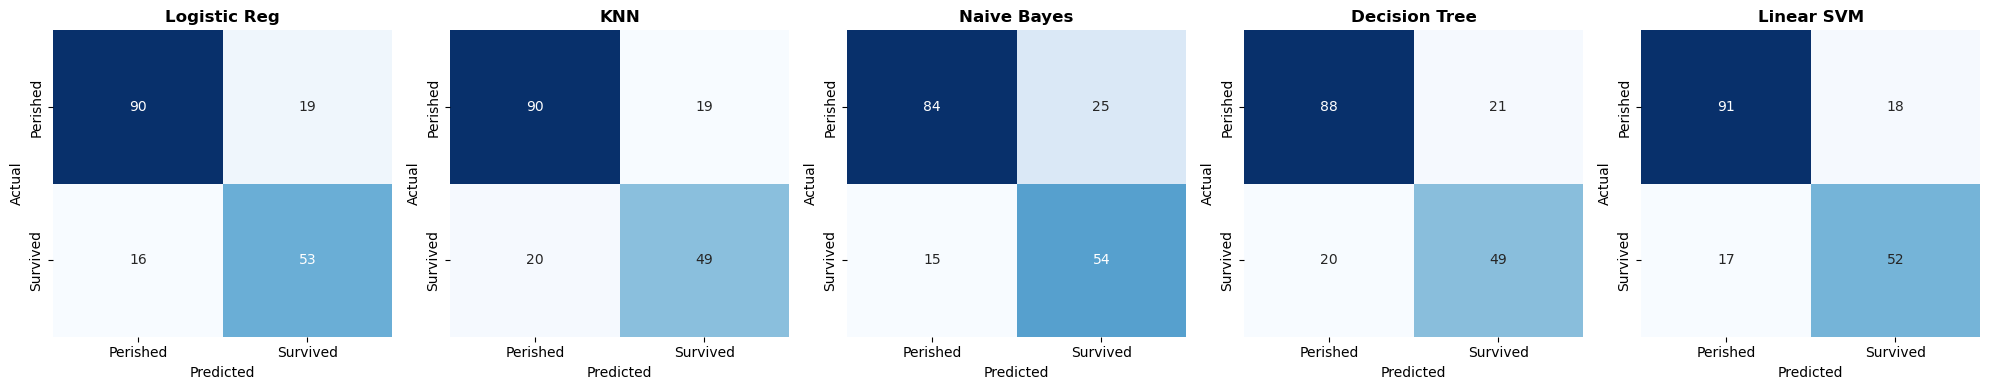

In [71]:
# Visualizing Confusion Matrices side-by-side
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
all_preds = [y_pred, y_pred_knn, y_pred_NB, y_pred_DT, y_pred_svc]
model_names = ['Logistic Reg', 'KNN', 'Naive Bayes', 'Decision Tree', 'Linear SVM']

for ax, preds, name in zip(axes, all_preds, model_names):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Perished', 'Survived'], yticklabels=['Perished', 'Survived'])
    ax.set_title(name, fontweight='bold')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

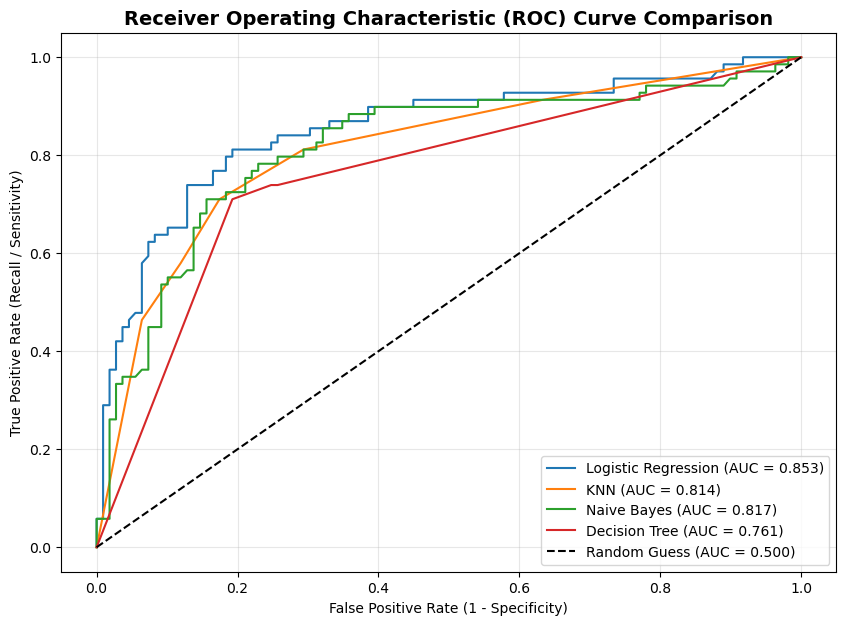

In [72]:
# ROC Curve Comparison
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(10, 7))
# Logistic Regression
fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test)[:, 1])
plt.plot(fpr, tpr, label=f'Logistic Regression (AUC = {auc(fpr, tpr):.3f})')

# KNN
fpr, tpr, _ = roc_curve(y_test, knn_model.predict_proba(X_test_scaled)[:, 1])
plt.plot(fpr, tpr, label=f'KNN (AUC = {auc(fpr, tpr):.3f})')

# Naive Bayes
fpr, tpr, _ = roc_curve(y_test, model_NB.predict_proba(X_test)[:, 1])
plt.plot(fpr, tpr, label=f'Naive Bayes (AUC = {auc(fpr, tpr):.3f})')

# Decision Tree
fpr, tpr, _ = roc_curve(y_test, model_DT.predict_proba(X_test_scaled)[:, 1])
plt.plot(fpr, tpr, label=f'Decision Tree (AUC = {auc(fpr, tpr):.3f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Guess (AUC = 0.500)')
plt.title('Receiver Operating Characteristic (ROC) Curve Comparison', fontsize=14, fontweight='bold')
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Recall / Sensitivity)')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.show()

### 💡 Crucial Concept: How Decision Trees, KNN, and SVM Support Regression

- **Decision Tree**: When switching to `DecisionTreeRegressor`, the splitting criterion changes from **Gini/Entropy** to **MSE / Variance Reduction**, and terminal leaves output the **mean continuous value** of samples in that partition instead of class mode.
- **KNN**: When switching to `KNeighborsRegressor`, instead of majority voting, it computes the **mean (or distance-weighted average)** of the target values of the $k$ nearest neighbors.
- **SVM**: When switching to `SVR`, instead of maximizing classification margins with hyperplanes, it fits an **$\epsilon$-insensitive tube** where errors smaller than $\epsilon$ are ignored and points outside the tube act as support vectors!

> 📌 *See the dedicated companion notebook `Algorithms_Supporting_Both_Classification_and_Regression.ipynb` in this directory for comprehensive code, mathematics, and curve visualizations for regression!*

### Top 15 Machine Learning Interview Questions: Classification

| # | Question | Expert Interview Answer |
|---|---|---|
| **1** | **Why is Accuracy a misleading metric for imbalanced data?** | If 99% of samples are healthy (0) and 1% have disease (1), a trivial dummy model that always predicts 0 achieves 99% accuracy while having 0% recall on the disease class. Use Precision, Recall, F1-Score, or PR-AUC instead. |
| **2** | **What is the mathematical formulation of F1-Score and why Harmonic Mean?** | $F_1 = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$. The harmonic mean penalizes extreme imbalances between Precision and Recall. If either metric is near 0, the harmonic mean plunges to 0, unlike the arithmetic mean. |
| **3** | **Explain the Precision-Recall tradeoff.** | By varying the classification decision threshold $\tau$ (default 0.5): Increasing $\tau \to 0.9$ ensures the model only flags instances it is highly confident about (Higher Precision, Lower Recall). Decreasing $\tau \to 0.1$ catches almost all positive cases (Higher Recall, Lower Precision). |
| **4** | **What is Specificity and False Positive Rate (FPR)?** | $\text{Specificity} = \frac{\text{TN}}{\text{TN} + \text{FP}}$ (True Negative Rate). $\text{FPR} = 1 - \text{Specificity} = \frac{\text{FP}}{\text{TN} + \text{FP}}$. ROC Curve plots $\text{TPR} = \text{Recall}$ vs $\text{FPR}$. |
| **5** | **How does the Sigmoid function work in Logistic Regression?** | $\sigma(z) = \frac{1}{1 + e^{-z}}$ maps any real-valued log-odds $z = w^T x + b$ into a valid probability $p \in (0, 1)$. Its derivative is convenient: $\sigma'(z) = \sigma(z)(1 - \sigma(z))$. |
| **6** | **What are the assumptions of Logistic Regression?** | (1) Binary or ordinal outcome, (2) Linearity between independent variables and the **log-odds** (logit) of the outcome, (3) Independence of observations, (4) Absence of high multicollinearity. Normal distribution of features is NOT required. |
| **7** | **Why does Naive Bayes assume conditional feature independence?** | It drastically simplifies Bayes' theorem: $P(X_1, X_2, \dots, X_p | Y) = \prod_{j=1}^p P(X_j | Y)$. This avoids estimating exponential joint probability tables, making training extremely fast $O(n \cdot p)$ even when independence is mildly violated. |
| **8** | **What is Laplace Smoothing in Naive Bayes?** | When a feature/word does not appear in the training data for a class, $P(X_j | Y) = 0$, which multiplies through and zeros out the entire posterior probability! Laplace smoothing adds a pseudocount $\alpha$ (typically $\alpha=1$): $\hat{P}(X_j | Y) = \frac{\text{count}(X_j) + \alpha}{\sum \text{counts} + \alpha K}$. |
| **9** | **What is Gini Impurity vs Information Gain / Entropy?** | $\text{Gini} = 1 - \sum p_k^2$, range $[0, 0.5]$ for binary. $\text{Entropy} = -\sum p_k \log_2 p_k$, range $[0, 1]$. Gini is computationally faster because it avoids computing logarithms; both lead to very similar tree splits in practice. |
| **10** | **What is the difference between Hard Margin and Soft Margin SVM?** | Hard Margin SVM strictly forbids any misclassification ($y_i(w^Tx_i + b) \ge 1$); only works for linearly separable data and is vulnerable to outliers. Soft Margin SVM introduces slack variables $\xi_i \ge 0$ with penalty parameter $C$ to tolerate bounded errors. |
| **11** | **What is K-Fold Stratified Cross Validation?** | In standard K-Fold, folds are chosen uniformly at random, which can lead to folds having unequal class distributions. Stratified K-Fold preserves the exact percentage of samples for each target class across every single fold. |
| **12** | **How do you interpret the coefficients of Logistic Regression?** | $e^{\beta_j}$ represents the **Odds Ratio**. A one-unit increase in $X_j$ multiplies the odds of the outcome by $e^{\beta_j}$, holding other features constant. If $\beta_j > 0$, $e^{\beta_j} > 1$, increasing the probability of class 1. |
| **13** | **What is the Brier Score?** | $\text{BS} = \frac{1}{n} \sum (\hat{p}_i - y_i)^2$. It measures the mean squared difference between predicted probabilities and actual binary outcomes. Lower is better, measuring probability calibration. |
| **14** | **What is Platt Scaling and Isotonic Regression?** | Post-processing calibration techniques that convert raw model margins/scores (e.g. from SVM or boosted trees) into well-calibrated true posterior probabilities. |
| **15** | **When should you use One-vs-Rest vs One-vs-One for Multi-class classification?** | OvR trains $K$ classifiers; preferred when $K$ is large or training is fast. OvO trains $\frac{K(K-1)}{2}$ classifiers; each classifier only trains on a subset of data with 2 classes, which is preferred for algorithms with non-linear complexity like kernel SVM ($O(n^2)$ to $O(n^3)$). |